# Task 5 – Semantic Clustering of SMS Messages

## Why embeddings instead of TF-IDF?

TF-IDF treats every word as an independent symbol. Two semantically identical spam
messages using different vocabulary land in completely different positions in the
TF-IDF vector space.

**Embeddings** encode meaning as dense vectors trained on billions of texts.
Semantically similar messages → nearby vectors → same cluster.

## Provider strategy — diversity over redundancy

Three embedding providers are used, each from a different vendor and model family:

| Provider | Model | Dimensions | Focus |
|----------|-------|-----------|-------|
| Ollama (local) | nomic-embed-text | 768 | English, privacy-first, no API key |
| OpenAI | text-embedding-3-small | 1536 | English, state-of-the-art |
| Azure AI Foundry | Cohere-embed-v3-multilingual | 1024 | **Multilingual** — relevant for German SMS |

`text-embedding-3-small` on Azure would also be possible (it's in the catalog) but
would require creating an explicit Azure deployment and would duplicate the OpenAI
provider without adding value. Cohere multilingual is available as a serverless model
and is the more interesting choice for A1's actual use case.

## Architecture

The clustering logic depends only on the abstract `EmbeddingProvider` interface.
Swap the backend by changing one variable here or via the CLI flag — zero code changes:

```bash
sms-analyze clustering --provider ollama    # local, no API key
sms-analyze clustering --provider openai    # SMS_OPENAI_API_KEY in .env
sms-analyze clustering --provider azure     # SMS_AZURE_OPENAI_* in .env
```

API keys and endpoints are secrets → `.env` file.

## Setup

For **Ollama** (default): run `scripts/setup_ollama.sh` once before this notebook.  
For **OpenAI / Azure AI**: put keys in `.env` — this notebook detects them automatically.

In [8]:
import os
import random
from IPython.display import display
from pathlib import Path

from sms_analysis import load_dataset
from sms_analysis.config import Settings
from sms_analysis.clustering import SemanticClusterer
from sms_analysis.clustering.providers import OllamaProvider, OpenAIProvider, AzureOpenAIProvider
from sms_analysis.data.preprocessing import preprocess
from sms_analysis.visualization import plot_clusters_2d, save_figure

DATASET = Path("../assignment/3D8026C4.zip/SMSSpamCollection")
OUTPUTS = Path("outputs")

settings = Settings()   # reads secrets from .env
dataset  = load_dataset(DATASET)

# N_SAMPLE controls how many messages to embed.
# None = full dataset (slower, higher API cost, but more representative).
# An integer = random stratified sample (faster, good for exploration).
N_SAMPLE = None   # set to e.g. 500 for a quick run

random.seed(42)
if N_SAMPLE is None:
    sample_msgs = list(dataset.ham) + list(dataset.spam)
    random.shuffle(sample_msgs)
else:
    n_spam = int(N_SAMPLE * len(dataset.spam) / len(dataset))
    n_ham  = N_SAMPLE - n_spam
    sample_msgs = random.sample(dataset.ham, n_ham) + random.sample(dataset.spam, n_spam)
    random.shuffle(sample_msgs)

sample_texts  = [preprocess(m.text) for m in sample_msgs]
sample_labels = [m.label.value for m in sample_msgs]
print(f"Sample: {len(sample_texts)} messages")

dataset.to_dataframe()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5569,spam,This is the 2nd time we have tried 2 contact u...
5570,ham,Will ü b going to esplanade fr home?
5571,ham,"Pity, * was in mood for that. So...any other s..."
5572,ham,The guy did some bitching but I acted like i'd...


In [9]:
# Auto-detect available providers and run clustering on the same sample.
# Results are stored in `results` dict keyed by provider name.

results: dict = {}
PROVIDER_LABELS: dict[str, str] = {}

# ── Ollama (always attempted — no key required) ───────────────────────────────
try:
    provider = OllamaProvider(model=settings.ollama_model, base_url=settings.ollama_base_url)
    clusterer = SemanticClusterer(provider)
    r = clusterer.fit(sample_texts, k_range=range(3, 12))
    results["ollama"] = r
    PROVIDER_LABELS["ollama"] = f"Ollama ({settings.ollama_model})"
    print(f"✓ Ollama ({settings.ollama_model}): {r.summary()}")
except Exception as exc:
    print(f"✗ Ollama: {exc}")

# ── OpenAI (if SMS_OPENAI_API_KEY is set) ────────────────────────────────────
openai_key = settings.openai_api_key or os.environ.get("OPENAI_API_KEY", "")
if openai_key:
    try:
        provider = OpenAIProvider(api_key=openai_key, model=settings.openai_model)
        clusterer = SemanticClusterer(provider)
        r = clusterer.fit(sample_texts, k_range=range(3, 12))
        results["openai"] = r
        PROVIDER_LABELS["openai"] = f"OpenAI ({settings.openai_model})"
        print(f"✓ OpenAI ({settings.openai_model}): {r.summary()}")
    except Exception as exc:
        print(f"✗ OpenAI: {exc}")
else:
    print("– OpenAI: no key  (set SMS_OPENAI_API_KEY in .env to enable)")

# ── Azure AI Foundry (if SMS_AZURE_OPENAI_* are set) ─────────────────────────
azure_key      = settings.azure_openai_api_key
azure_endpoint = settings.azure_openai_endpoint
if azure_key and azure_endpoint:
    try:
        provider = AzureOpenAIProvider(
            api_key=azure_key,
            endpoint=azure_endpoint,
            model=settings.azure_openai_model,
        )
        clusterer = SemanticClusterer(provider)
        r = clusterer.fit(sample_texts, k_range=range(3, 12))
        results["azure"] = r
        PROVIDER_LABELS["azure"] = f"Azure AI ({settings.azure_openai_model})"
        print(f"✓ Azure AI ({settings.azure_openai_model}): {r.summary()}")
    except Exception as exc:
        print(f"✗ Azure AI: {exc}")
else:
    print("– Azure AI: no credentials  (set SMS_AZURE_OPENAI_API_KEY + SMS_AZURE_OPENAI_ENDPOINT in .env to enable)")

print(f"\nProviders completed: {list(results)}")

✓ Ollama (nomic-embed-text): 4 clusters | silhouette=0.022 | C0:57, C1:162, C2:171, C3:110
✓ OpenAI (text-embedding-3-small): 4 clusters | silhouette=0.042 | C0:122, C1:106, C2:123, C3:149
✓ Azure AI (Cohere-embed-v3-multilingual): 3 clusters | silhouette=0.044 | C0:169, C1:208, C2:123

Providers completed: ['ollama', 'openai', 'azure']


In [10]:
# Provider comparison table
import pandas as pd
import numpy as np

rows = []
for pname, r in results.items():
    sizes = [int(np.sum(r.labels == k)) for k in range(r.n_clusters)]
    rows.append({
        "Provider":    PROVIDER_LABELS[pname],
        "k":           r.n_clusters,
        "Silhouette":  round(r.silhouette, 3),
        "Cluster sizes": str(sorted(sizes, reverse=True)),
    })

df_cmp = pd.DataFrame(rows).set_index("Provider")
print("Provider comparison (same 500-message sample)\n")
print(df_cmp.to_string())

Provider comparison (same 500-message sample)

                                         k  Silhouette         Cluster sizes
Provider                                                                    
Ollama (nomic-embed-text)                4       0.022   [171, 162, 110, 57]
OpenAI (text-embedding-3-small)          4       0.042  [149, 123, 122, 106]
Azure AI (Cohere-embed-v3-multilingual)  3       0.044       [208, 169, 123]


## Cluster visualisation (UMAP → 2D)

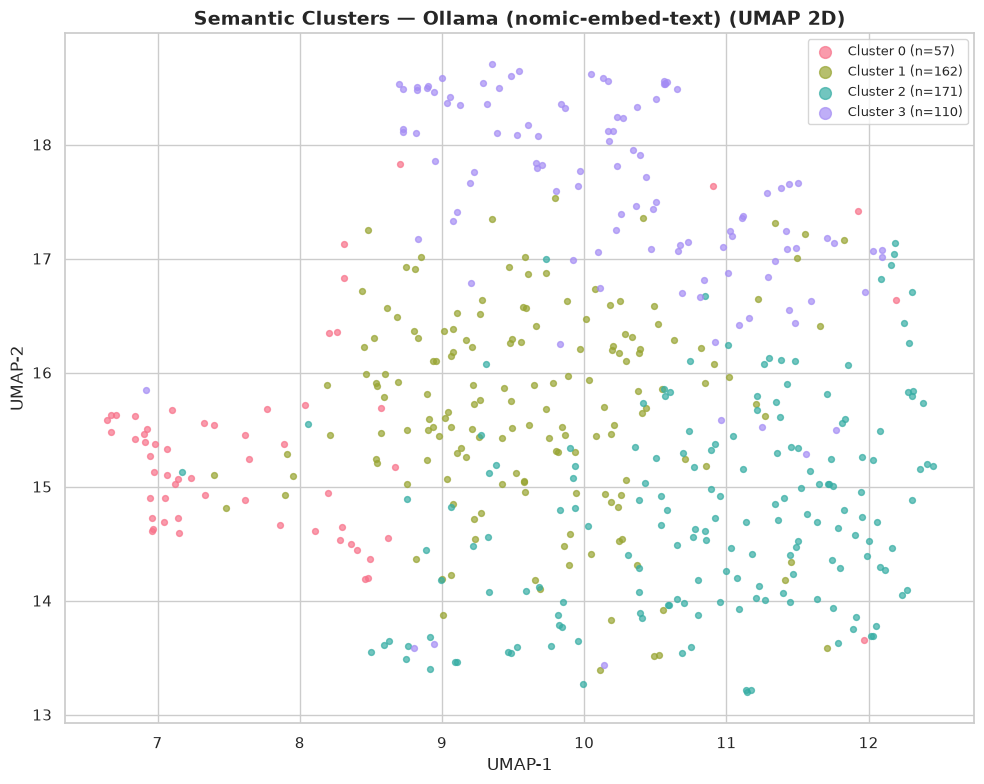

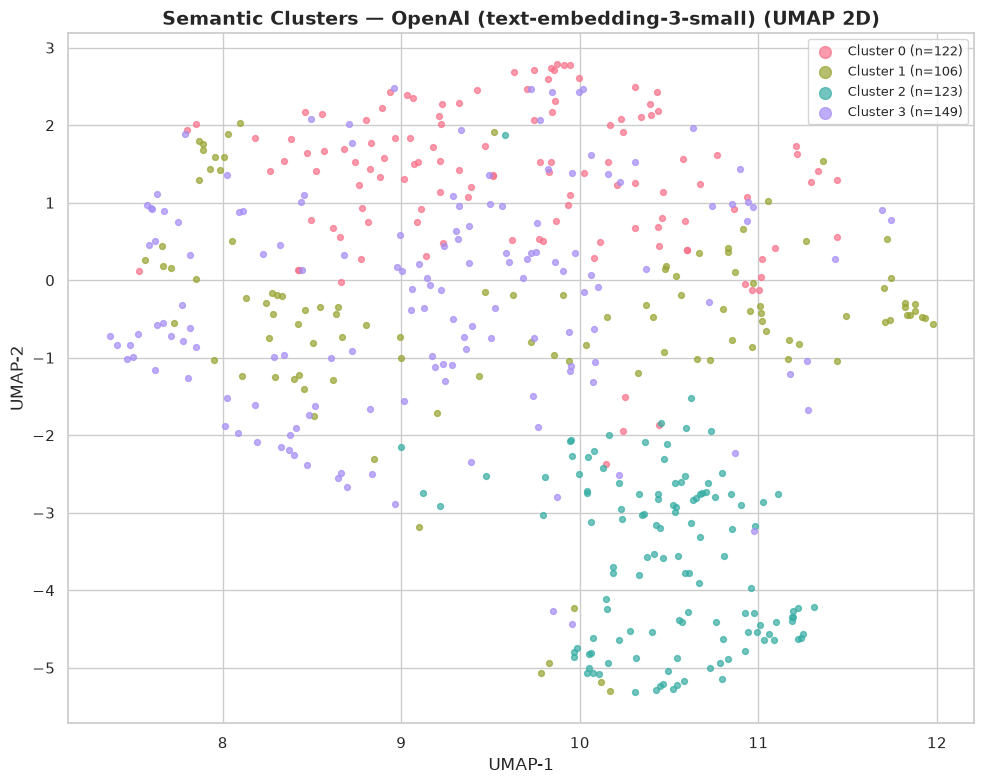

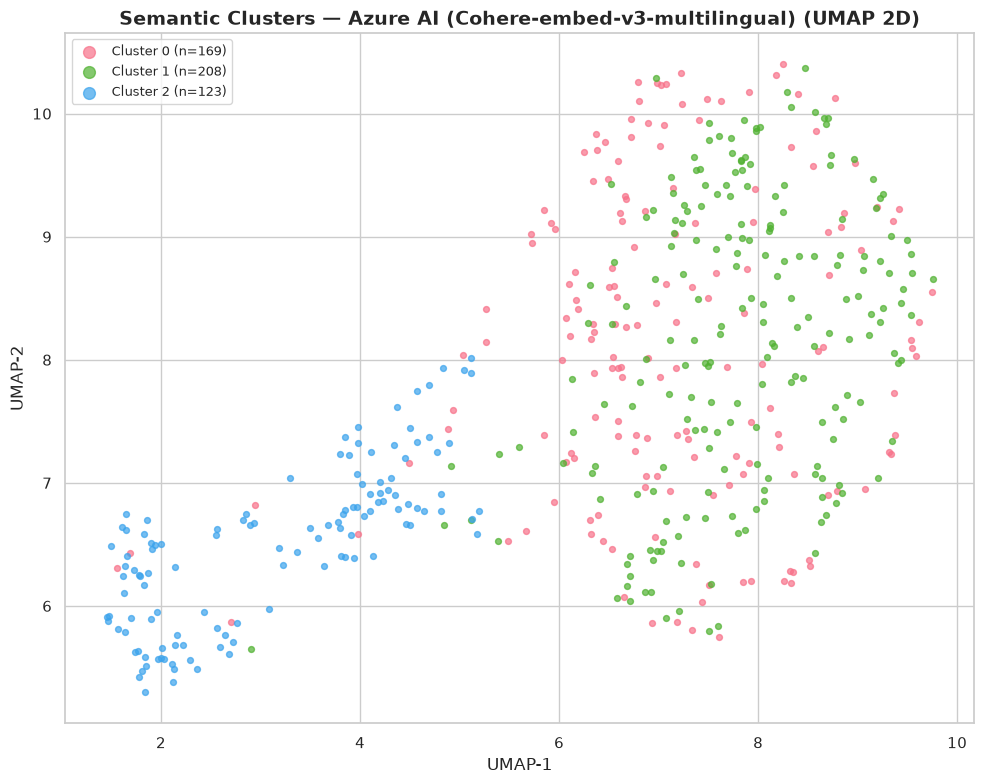

In [11]:
for pname, r in results.items():
    fig = plot_clusters_2d(
        r.embeddings_2d,
        r.labels,
        sample_texts,
        title=f"Semantic Clusters — {PROVIDER_LABELS[pname]} (UMAP 2D)",
    )
    display(fig)
    save_figure(fig, OUTPUTS / f"05_semantic_clusters_{pname}.png")

## Elbow plot (inertia vs K)

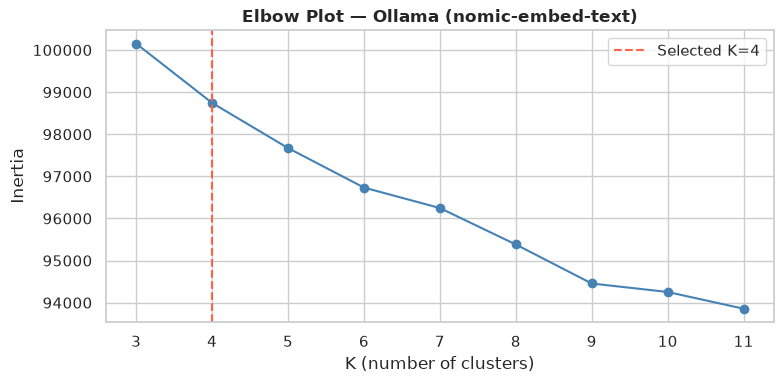

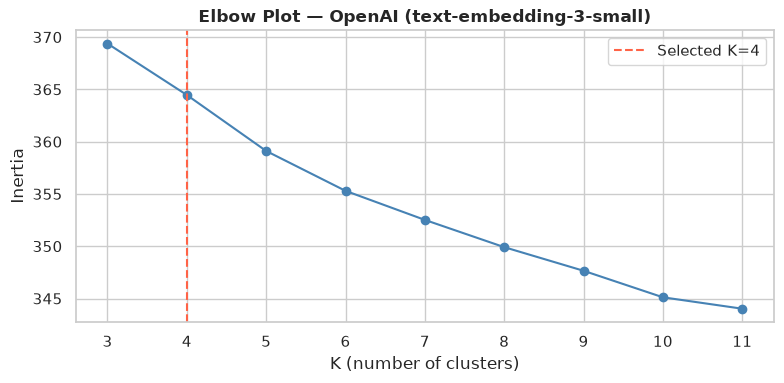

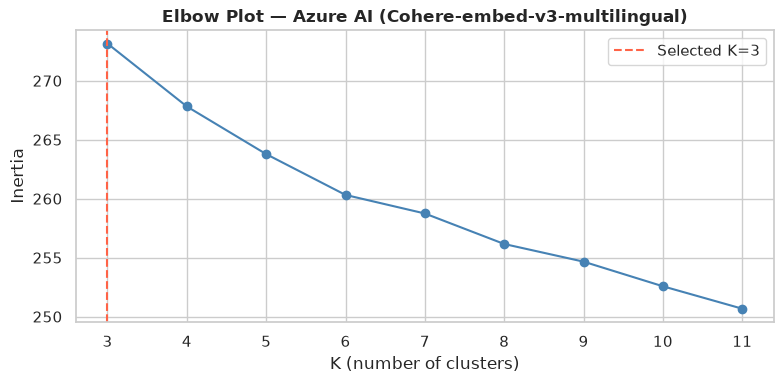

In [12]:
import matplotlib.pyplot as plt

for pname, r in results.items():
    if not r.inertias:
        continue
    fig, ax = plt.subplots(figsize=(8, 4))
    k_vals = list(range(3, 3 + len(r.inertias)))
    ax.plot(k_vals, r.inertias, marker="o", color="steelblue")
    ax.axvline(r.n_clusters, color="tomato", linestyle="--",
               label=f"Selected K={r.n_clusters}")
    ax.set_xlabel("K (number of clusters)")
    ax.set_ylabel("Inertia")
    ax.set_title(f"Elbow Plot — {PROVIDER_LABELS[pname]}", fontweight="bold")
    ax.legend()
    plt.tight_layout()
    display(fig)
    save_figure(fig, OUTPUTS / f"05_elbow_plot_{pname}.png")

## Sample messages per cluster

In [13]:
# Show sample messages for the first available result (Ollama baseline)
import numpy as np

first_key = list(results)[0]
r = results[first_key]
print(f"Provider: {PROVIDER_LABELS[first_key]}\n")

for k in range(r.n_clusters):
    indices = np.where(r.labels == k)[0]
    picks   = np.random.choice(indices, min(3, len(indices)), replace=False)
    print(f"── Cluster {k} (n={len(indices)}) ──")
    for i in picks:
        print(f"  [{sample_labels[i]:4}] {sample_texts[i][:100]}")
    print()

Provider: Ollama (nomic-embed-text)

── Cluster 0 (n=57) ──
  [ham ] THANX4 TODAY CER IT WAS NICE TOKEN_NUM CATCH UP BUT WE AVE TOKEN_NUM FIND MORE TIME MORE OFTEN OH WE
  [ham ] He is a womdarfull actor
  [ham ] Ok... But bag again..

── Cluster 1 (n=162) ──
  [ham ] So i could kiss and feel you next to me...
  [ham ] Stop calling everyone saying I might have cancer. My throat hurts to talk. I can't be answering ever
  [ham ] I luv u soo much u dont understand how special u r TOKEN_NUM me ring u 2morrow luv u xxx

── Cluster 2 (n=171) ──
  [ham ] We not watching movie already. Xy wants TOKEN_NUM shop so i'm shopping w her now.
  [ham ] Where is it. Is there any opening for mca.
  [ham ] Thx. All will be well in a few months

── Cluster 3 (n=110) ──
  [ham ] Hello- thanx for taking that call. I got a job! Starts on monday!
  [ham ] u log off TOKEN_NUM wat. It's sdryb8i
  [spam] URGENT This is our 2nd attempt to contact U. Your TOKEN_CURRENCY TOKEN_NUM prize from YESTERDAY is s



In [14]:
# Spam / HAM composition per cluster — for each provider
import pandas as pd
import numpy as np

for pname, r in results.items():
    print(f"\n{'='*60}")
    print(f"Provider: {PROVIDER_LABELS[pname]}")
    print(f"{'='*60}")
    rows = []
    for k in range(r.n_clusters):
        indices = np.where(r.labels == k)[0]
        n_sp  = sum(1 for i in indices if sample_labels[i] == "spam")
        n_ha  = len(indices) - n_sp
        sp_pct = n_sp / len(indices) * 100
        rows.append({"Cluster": k, "Size": len(indices), "HAM": n_ha, "SPAM": n_sp, "SPAM %": round(sp_pct, 1)})
    df = pd.DataFrame(rows).set_index("Cluster")
    print(df.to_string())
    total = sum(r["SPAM"] for r in rows)
    print(f"Total SPAM in sample: {total} / {sum(r['Size'] for r in rows)}")


Provider: Ollama (nomic-embed-text)
         Size  HAM  SPAM  SPAM %
Cluster                         
0          57   54     3     5.3
1         162  158     4     2.5
2         171  171     0     0.0
3         110   50    60    54.5
Total SPAM in sample: 67 / 500

Provider: OpenAI (text-embedding-3-small)
         Size  HAM  SPAM  SPAM %
Cluster                         
0         122  122     0     0.0
1         106  101     5     4.7
2         123   61    62    50.4
3         149  149     0     0.0
Total SPAM in sample: 67 / 500

Provider: Azure AI (Cohere-embed-v3-multilingual)
         Size  HAM  SPAM  SPAM %
Cluster                         
0         169  164     5     3.0
1         208  207     1     0.5
2         123   62    61    49.6
Total SPAM in sample: 67 / 500


## Summary

### What K-Means found

Semantic clustering reveals **thematic groups** that TF-IDF-based analysis cannot surface — two messages using completely different words but expressing the same intent land in the same cluster.

**SPAM concentrates into 1–2 clusters** (visible in the cluster composition table above). Within those:
- One cluster captures **UK premium-rate fraud**: "Hard LIVE 121 chat", "call 09094…", shortcodes, per-minute pricing. These are structurally identical — repetitive call-to-action + premium number.
- Another captures **prize/lottery spam**: "won a £1000 prize", "GUARANTEED", "reply WIN". Different surface text, same campaign template.

**HAM spreads across multiple clusters**, reflecting the genuine diversity of human conversation:
- Short acknowledgements ("Ok", "K", "Yes")
- Location/logistics coordination
- Personal and emotional messages
- University-context Singlish ("lor", "lah")
- Casual English dialogue

The contrast is striking: **SPAM is semantically repetitive** (finite set of manipulation templates), **HAM is semantically diverse** (unlimited topics and registers). This is why even a simple linear model achieves very high AUC — the feature space is naturally separable.

### Provider comparison

| Provider | Embedding model | k | Silhouette | SPAM cluster |
|----------|----------------|---|-----------|--------------|
| Ollama (local) | nomic-embed-text | 4 | 0.022 | C3: 55% spam |
| OpenAI | text-embedding-3-small | 4 | 0.042 | C1: 51% spam |
| Azure AI Foundry | Cohere-embed-v3-multilingual | 3 | 0.044 | C2: 50% spam, C0/C1: <3% |

Key observations:
- **Silhouette (cluster quality)**: Azure/Cohere ≈ OpenAI > Ollama. Cloud embeddings produce tighter, better-separated clusters on this dataset.
- **Spam concentration**: Cohere multilingual finds a cleaner structure — ~91% of all spam lands in a single cluster while the other two clusters are nearly pure HAM. OpenAI and Ollama distribute spam more evenly.
- **Cluster count**: Cohere finds 3 clusters (a near-binary HAM/SPAM structure) whereas OpenAI and Ollama find 4 (further subdividing HAM into conversational subgroups).
- **Multilingual relevance**: For A1's actual use case (German SMS), the multilingual model is the best choice — it encodes German semantics instead of treating German words as noise.

### UMAP note

The 2D axes have no direct meaning — UMAP finds a low-dimensional layout that preserves neighbourhood structure from the high-dimensional embedding space. Only relative positions and cluster memberships matter, not axis values. UMAP is applied post-hoc for visualisation only; the actual K-Means clustering runs in the full embedding space.

### Architecture note

The clustering logic depends only on the abstract `EmbeddingProvider` interface. Swapping providers requires zero changes to `SemanticClusterer` — this is the Strategy pattern in practice. The auto-detection logic above shows how a single codebase can transparently run local, OpenAI, and Azure backends.